<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Recurrent Neural Networks (RNNs)

_Author:_ Tim Book, Riley Dallas

---


### Learning Objectives

- Learn how to train/test split for sequence data
- Use `TimeseriesGenerator` to prep our time series data for modeling
- Create a basic RNN model using `keras`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, GRU
from tensorflow.keras.utils import timeseries_dataset_from_array

In [2]:
# from google.colab import files
# _ = files.upload()

In [3]:
aapl = pd.read_csv('AAPL.csv')
aapl.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2005-04-25,5.212857,5.288571,5.158571,5.282857,3.522625,186615100
1,2005-04-26,5.254286,5.358572,5.160000,5.170000,3.447372,202626900
2,2005-04-27,5.127143,5.194286,5.072857,5.135714,3.424510,153472200
3,2005-04-28,5.184286,5.191429,5.034286,5.077143,3.385454,143776500
4,2005-04-29,5.164286,5.175714,5.031428,5.151429,3.434988,167907600


In [4]:
# How can we get tomorrow's stock closing stock price as a target?
# We shift the Close price and do some quick math.
aapl['close_tomorrow'] = aapl['Close'].shift(-1)
aapl['target'] = 1*(aapl['close_tomorrow'] - aapl['Close'] > 0)
aapl.dropna(inplace=True)

In [5]:
aapl.head()

,Date,Open,High,Low,Close,Adj Close,Volume,close_tomorrow,target
0,2005-04-25,5.212857,5.288571,5.158571,5.282857,3.522625,186615100,5.170000,0
1,2005-04-26,5.254286,5.358572,5.160000,5.170000,3.447372,202626900,5.135714,0
2,2005-04-27,5.127143,5.194286,5.072857,5.135714,3.424510,153472200,5.077143,0
3,2005-04-28,5.184286,5.191429,5.034286,5.077143,3.385454,143776500,5.151429,1
4,2005-04-29,5.164286,5.175714,5.031428,5.151429,3.434988,167907600,5.204286,1


In [6]:
# Construct X, y
xvars = ['Open', 'High', 'Low', 'Close', 'Volume']
X = aapl[xvars]
y = aapl['target']

In [7]:
y.value_counts()

1    1854
0    1668
Name: target, dtype: int64

In [8]:
X.shape

(3522, 5)

In [9]:
# TTS and Scale!
X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False)
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

In [10]:
X_train_sc[:5]

array([[-1.19435063, -1.19638267, -1.19127328, -1.19249719,  0.34270558],
       [-1.19319193, -1.19443969, -1.19123295, -1.1956559 ,  0.50452571],
       [-1.19674791, -1.19899969, -1.19369222, -1.19661552,  0.00775332],
       [-1.19514971, -1.19907899, -1.19478073, -1.19825484, -0.09023438],
       [-1.19570908, -1.19951518, -1.19486138, -1.19617568,  0.15364188]])

### timeseries_dataset_from_array()
Check out the docs [here](https://www.tensorflow.org/api_docs/python/tf/keras/utils/timeseries_dataset_from_array).

In [11]:
# Here, we'll make our data generators for the train and validation sets.
batch_size = 128
seq_len = 10

train_gen = timeseries_dataset_from_array(
    data=X_train_sc,
    targets=y_train,
    sequence_length=seq_len,
    batch_size=batch_size
)

val_gen = timeseries_dataset_from_array(
    data=X_test_sc,
    targets=y_test,
    sequence_length=seq_len,
    batch_size=batch_size
)

In [12]:
# How does this work?
for x_batch, y_batch in train_gen:
    break

In [13]:
x_batch.shape

TensorShape([128, 10, 5])

In [14]:
y_batch.shape

TensorShape([128])

In [15]:
# Let's create a model with two LSTM layers and a Dense layer.
# Let's go nuts here - the results might surprise you! (or not)
model = Sequential()
model.add(LSTM(128, return_sequences=True, input_shape=(10, 5)))
model.add(LSTM(64))
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1))

In [16]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 10, 128)           68608     
                                                                 
 lstm_1 (LSTM)               (None, 64)                49408     
                                                                 
 dense (Dense)               (None, 32)                2080      
                                                                 
 dropout (Dropout)           (None, 32)                0         
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 120,129
Trainable params: 120,129
Non-trainable params: 0
_________________________________________________________________


In [17]:
# Compile
model.compile(loss='bce', optimizer='rmsprop', metrics=['acc'])

In [18]:
# Fit
model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20
)

Epoch 1/20
21/21 [==============================] - 8s 114ms/step - loss: 1.2590 - acc: 0.4772 - val_loss: 0.8281 - val_acc: 0.4679
Epoch 2/20
21/21 [==============================] - 1s 39ms/step - loss: 0.9898 - acc: 0.4909 - val_loss: 0.6904 - val_acc: 0.5092
Epoch 3/20
21/21 [==============================] - 1s 43ms/step - loss: 0.7933 - acc: 0.4947 - val_loss: 0.6968 - val_acc: 0.4839
Epoch 4/20
21/21 [==============================] - 1s 41ms/step - loss: 0.9783 - acc: 0.4924 - val_loss: 0.7553 - val_acc: 0.4679
Epoch 5/20
21/21 [==============================] - 1s 44ms/step - loss: 0.9878 - acc: 0.4928 - val_loss: 0.7021 - val_acc: 0.4679
Epoch 6/20
21/21 [==============================] - 1s 42ms/step - loss: 0.8214 - acc: 0.4821 - val_loss: 0.7538 - val_acc: 0.5321
Epoch 7/20
21/21 [==============================] - 1s 44ms/step - loss: 1.6118 - acc: 0.4897 - val_loss: 0.7106 - val_acc: 0.4679
Epoch 8/20
21/21 [==============================] - 1s 39ms/step - loss: 0.8309 - 

# Ok then... let's try something a little more predictable!
(The weather!)

We'll work with data recorded at the weather station at the Max Planck Institute for Biogeochemistry in Jena, Germany.

In [19]:
jena = pd.read_csv('jena_2009_2010.csv')
jena.head()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,2009-01-01 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,2009-01-01 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,2009-01-01 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,2009-01-01 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,2009-01-01 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


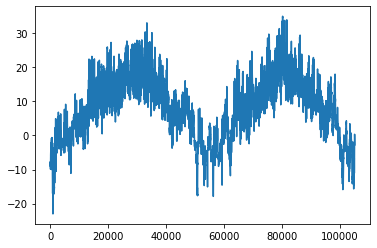

In [20]:
plt.plot(jena['T (degC)']);

In [21]:
# We're going to take the future temperature 24 hours in the future
# as our target. 
# 144 rows = 1440 min = 24 hours
jena['tomorrow_temp'] = jena['T (degC)'].shift(-144)
jena.dropna(inplace=True)
jena.head()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg),tomorrow_temp
0,2009-01-01 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3,-4.60
1,2009-01-01 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1,-4.67
2,2009-01-01 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6,-4.66
3,2009-01-01 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0,-4.55
4,2009-01-01 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3,-4.43


In [22]:
X = jena.drop(columns=['Date Time'])
y = jena['tomorrow_temp']

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False)

sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

In [23]:
X.head()

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg),tomorrow_temp
0,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3,-4.60
1,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1,-4.67
2,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6,-4.66
3,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0,-4.55
4,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3,-4.43


In [24]:
y.head()

0   -4.60
1   -4.67
2   -4.66
3   -4.55
4   -4.43
Name: tomorrow_temp, dtype: float64

In [25]:
# This dataset is big, so I'm going to take Francois Chollet's
# advice on this:
seq_len = 120
batch_size = 256

# Take only one obs per hour
sampling_rate = 6 

train_gen = timeseries_dataset_from_array(
    X_train_sc,
    y_train,
    sequence_length=seq_len,
    sampling_rate=sampling_rate,
    batch_size=batch_size
)

val_gen = timeseries_dataset_from_array(
    X_test_sc,
    y_test,
    sequence_length=seq_len,
    sampling_rate=sampling_rate,
    batch_size=batch_size
)

In [26]:
# We'll see some success with only a moderate model here
# Two LSTMs directly into a dense output.
model = Sequential()
model.add(LSTM(32, return_sequences=True, input_shape=(seq_len, X_train.shape[1])))
model.add(LSTM(32))
model.add(Dense(1))

In [27]:
# Compile
model.compile(loss='mse', optimizer='rmsprop', metrics=['mae'])

In [28]:
# Fit (save history)
history = model.fit(train_gen, validation_data=val_gen, epochs=10)

Epoch 1/10
306/306 [==============================] - 19s 53ms/step - loss: 51.5847 - mae: 5.5921 - val_loss: 47.4010 - val_mae: 5.2100
Epoch 2/10
306/306 [==============================] - 15s 50ms/step - loss: 29.2409 - mae: 4.1189 - val_loss: 35.6655 - val_mae: 4.5010
Epoch 3/10
306/306 [==============================] - 15s 50ms/step - loss: 22.0444 - mae: 3.6060 - val_loss: 28.8282 - val_mae: 4.1732
Epoch 4/10
306/306 [==============================] - 16s 54ms/step - loss: 19.1926 - mae: 3.3970 - val_loss: 22.4792 - val_mae: 3.5911
Epoch 5/10
306/306 [==============================] - 16s 53ms/step - loss: 16.8276 - mae: 3.1424 - val_loss: 19.6929 - val_mae: 3.3723
Epoch 6/10
306/306 [==============================] - 15s 50ms/step - loss: 13.7481 - mae: 2.8438 - val_loss: 15.8373 - val_mae: 3.0044
Epoch 7/10
306/306 [==============================] - 16s 51ms/step - loss: 11.8256 - mae: 2.5919 - val_loss: 13.1108 - val_mae: 2.5885
Epoch 8/10
306/306 [============================

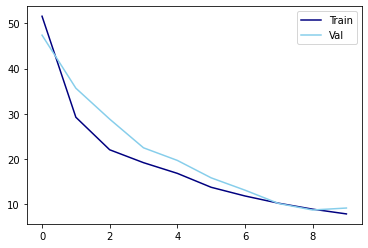

In [29]:
# Plot our loss chart - what do we see?
plt.plot(history.history['loss'], c='navy', label='Train')
plt.plot(history.history['val_loss'], c='skyblue', label='Val')
plt.legend();